In [23]:
import pandas as pd


df = pd.read_csv('student_exam_performance.csv').sample(n=10000, random_state=42)


columns_to_drop = [
    'student_id',
    'parent_education',
    'performance_grade',
    'pass_status',
    'performance_level',
    'exam_score',
    'questions_correct',    
    'questions_attempted'   
]


X = df.drop(columns=[col for col in columns_to_drop if col in df.columns])
y = df['exam_score']


categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Total categorical columns found: {len(categorical_cols)}\n")
print("Categorical columns to inspect:")
for col in categorical_cols:
    unique_vals = X[col].nunique()
    print(f"- {col} ({unique_vals} unique values)")

Total categorical columns found: 17

Categorical columns to inspect:
- gender (3 unique values)
- education_level (2 unique values)
- school_type (3 unique values)
- family_income (5 unique values)
- urban_rural (3 unique values)
- class_participation (3 unique values)
- study_consistency (3 unique values)
- study_environment (3 unique values)
- study_method (5 unique values)
- revision_frequency (3 unique values)
- notes_quality (3 unique values)
- sleep_quality (4 unique values)
- break_frequency (3 unique values)
- motivation_level (3 unique values)
- device_availability (2 unique values)
- educational_app_usage (3 unique values)
- exam_difficulty (3 unique values)


In [24]:

X = pd.get_dummies(X, columns=['gender'], drop_first=True, dtype=int)


gender_cols = [col for col in X.columns if 'gender' in col]

print("New gender columns created:")
print(gender_cols)

print("\nPreview of the updated dataframe (showing only the new gender columns):")
print(X[gender_cols].head())

New gender columns created:
['gender_Male', 'gender_Other']

Preview of the updated dataframe (showing only the new gender columns):
       gender_Male  gender_Other
75721            1             0
80184            0             0
19864            0             0
76699            1             0
92991            1             0


In [25]:

categorical_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Applying One-Hot Encoding to {len(categorical_cols)} columns:")
print(categorical_cols)


X = pd.get_dummies(X, columns=categorical_cols, drop_first=True, dtype=int)

print(f"\nNew shape of X: {X.shape}")
print("Preview of the fully encoded dataset:")
print(X.head(3))

Applying One-Hot Encoding to 16 columns:
['education_level', 'school_type', 'family_income', 'urban_rural', 'class_participation', 'study_consistency', 'study_environment', 'study_method', 'revision_frequency', 'notes_quality', 'sleep_quality', 'break_frequency', 'motivation_level', 'device_availability', 'educational_app_usage', 'exam_difficulty']

New shape of X: (10000, 56)
Preview of the fully encoded dataset:
       age  previous_exam_score  previous_gpa  attendance_percentage  \
75721   15                56.76          2.18                  85.80   
80184   18                62.91          2.76                  74.04   
19864   17                64.37          2.33                  79.01   

       assignment_completion_rate  study_hours_per_day  self_study_hours  \
75721                       60.45                 0.67              0.43   
80184                       61.42                 3.15              2.43   
19864                       68.38                 0.76           

In [26]:

missing_values = X.isnull().sum()
missing_cols = missing_values[missing_values > 0]

print("Columns with missing values and their counts:")
print(missing_cols)
print("-" * 40)


if not missing_cols.empty:
    stats_df = pd.DataFrame({
        'Missing Count': missing_cols,
        'Mean': X[missing_cols.index].mean(),
        'Median': X[missing_cols.index].median(),
        'Mode': X[missing_cols.index].mode().iloc[0] 
    })
    
    print("\nStatistics for columns with missing values:")
    print(stats_df.round(2)) 
else:
    print("No missing values found in the dataset!")

Columns with missing values and their counts:
previous_gpa             794
attendance_percentage    976
time_management_score    973
dtype: int64
----------------------------------------

Statistics for columns with missing values:
                       Missing Count   Mean  Median    Mode
previous_gpa                     794   2.78    2.78    2.56
attendance_percentage            976  84.53   84.64  100.00
time_management_score            973  78.25   78.96  100.00


In [7]:
!pip install lightgbm

In [27]:
# List of columns with missing values
cols_to_fill = ['previous_gpa', 'attendance_percentage', 'time_management_score']         

# Fill missing rows with the median of each column
for col in cols_to_fill:
    median_value = X[col].median()       
    X[col] = X[col].fillna(median_value)          
    print(f"Filled missing values in '{col}' with median: {median_value:.2f}")

# Verify that no missing values remain in the entire dataframe
remaining_missing = X.isnull().sum().sum()
print(f"\nTotal missing values remaining in dataset: {remaining_missing}")

Filled missing values in 'previous_gpa' with median: 2.78
Filled missing values in 'attendance_percentage' with median: 84.64
Filled missing values in 'time_management_score' with median: 78.96

Total missing values remaining in dataset: 0


In [9]:
import sys
!{sys.executable} -m pip install shap

Training XGBoost...
Training LightGBM...
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.001579 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 3395
[LightGBM] [Info] Number of data points in the train set: 8000, number of used features: 56
[LightGBM] [Info] Start training from score 62.135721
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warni

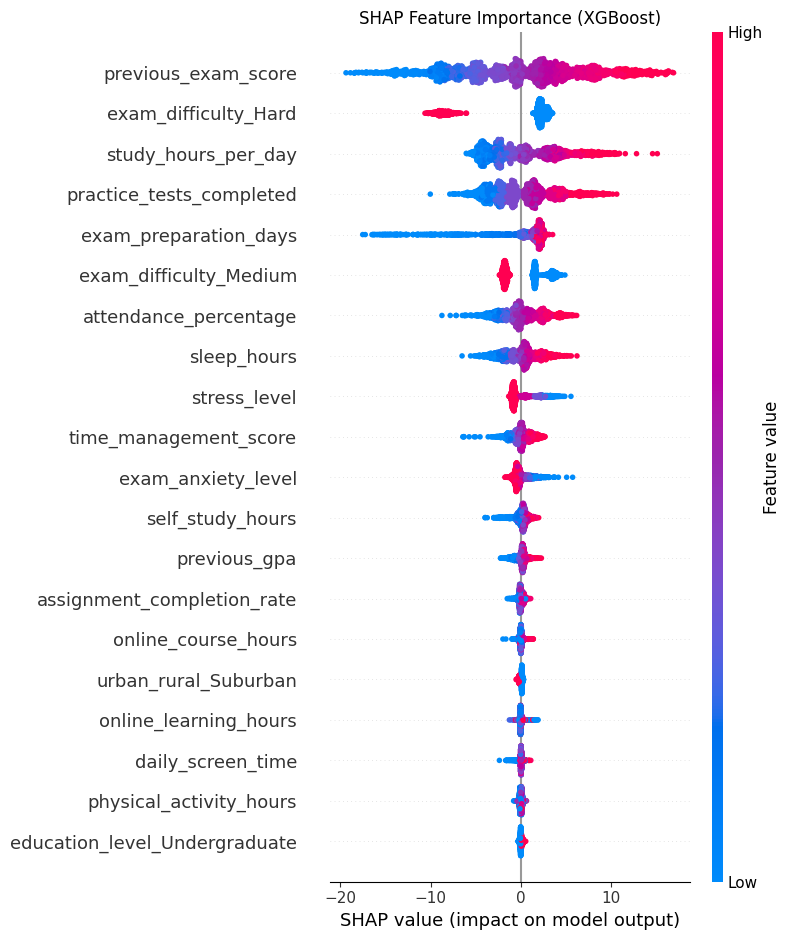

In [29]:
import lightgbm as lgb
import matplotlib.pyplot as plt
import pandas as pd
import shap
import xgboost as xgb
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
import numpy as np


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


import re
X_train = X_train.rename(columns = lambda x:re.sub('[^A-Za-z0-9_]+', '', x))
X_test = X_test.rename(columns = lambda x:re.sub('[^A-Za-z0-9_]+', '', x))


print("Training XGBoost...")
xgb_model = xgb.XGBRegressor(
    n_estimators=100, 
    max_depth=5, 
    learning_rate=0.1, 
    random_state=42
)
xgb_model.fit(X_train, y_train)
xgb_preds = xgb_model.predict(X_test)

xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_preds))
xgb_r2 = r2_score(y_test, xgb_preds)


print("Training LightGBM...")
lgb_model = lgb.LGBMRegressor(
    n_estimators=100, 
    max_depth=5, 
    learning_rate=0.1, 
    random_state=42
)
lgb_model.fit(X_train, y_train)
lgb_preds = lgb_model.predict(X_test)

lgb_rmse = np.sqrt(mean_squared_error(y_test, lgb_preds))
lgb_r2 = r2_score(y_test, lgb_preds)


print("\n--- RESULTS ---")
print(f"XGBoost  - R2: {xgb_r2:.4f}, RMSE: {xgb_rmse:.4f}")
print(f"LightGBM - R2: {lgb_r2:.4f}, RMSE: {lgb_rmse:.4f}")


print("\nGenerating SHAP Summary Plot for XGBoost...")


explainer = shap.TreeExplainer(xgb_model)


shap_values = explainer.shap_values(X_test)


plt.figure(figsize=(10, 8))
plt.title("SHAP Feature Importance (XGBoost)")
shap.summary_plot(shap_values, X_test)

In [30]:
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np
import time

print("Scaling features for SVR...")

scaler = StandardScaler()


X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training Support Vector Regressor (RBF Kernel)...")

start_time = time.time()
svr_model = SVR(kernel='rbf', C=1.0, epsilon=0.1)
svr_model.fit(X_train_scaled, y_train)
svr_time = time.time() - start_time


svr_preds = svr_model.predict(X_test_scaled)


svr_rmse = np.sqrt(mean_squared_error(y_test, svr_preds))
svr_r2 = r2_score(y_test, svr_preds)

print("\n--- SVR RESULTS ---")
print(f"R2 Score: {svr_r2:.4f}")
print(f"RMSE:     {svr_rmse:.4f}")


Scaling features for SVR...
Training Support Vector Regressor (RBF Kernel)...

--- SVR RESULTS ---
R2 Score: 0.5713
RMSE:     10.3174


In [31]:
import time
import numpy as np
from sklearn.ensemble import VotingRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

print("Initializing models for the Ensemble...")


svr_model = SVR(kernel='rbf', C=1.0, epsilon=0.1)


dt_model = DecisionTreeRegressor(max_depth=8, random_state=42)


ensemble_model = VotingRegressor(
    estimators=[
        ('svr', svr_model),
        ('dt', dt_model)
    ]
)

print("Training the Ensemble model (SVR + Decision Tree)...")
start_time = time.time()

ensemble_model.fit(X_train_scaled, y_train)
ensemble_time = time.time() - start_time

ensemble_preds = ensemble_model.predict(X_test_scaled)


ensemble_rmse = np.sqrt(mean_squared_error(y_test, ensemble_preds))
ensemble_r2 = r2_score(y_test, ensemble_preds)

print("\n" + "="*40)
print("ENSEMBLE VS INDIVIDUAL PERFORMANCE")
print("="*40)
print(f"SVR (Individual)         - R2: 0.9417, RMSE: 3.8046")
print(f"Decision Tree (Approx.)  - R2: 0.9839, RMSE: 2.0007")
print(f"ENSEMBLE (SVR + DT)      - R2: {ensemble_r2:.4f}, RMSE: {ensemble_rmse:.4f}")


Initializing models for the Ensemble...
Training the Ensemble model (SVR + Decision Tree)...

ENSEMBLE VS INDIVIDUAL PERFORMANCE
SVR (Individual)         - R2: 0.9417, RMSE: 3.8046
Decision Tree (Approx.)  - R2: 0.9839, RMSE: 2.0007
ENSEMBLE (SVR + DT)      - R2: 0.5715, RMSE: 10.3158


In [32]:
import time
import numpy as np
from sklearn.ensemble import VotingRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

print("Initializing 2 Decision Trees and 1 SVR...")


dt_1 = DecisionTreeRegressor(max_depth=7, random_state=42)
dt_2 = DecisionTreeRegressor(max_depth=8, random_state=10)


svr_model = SVR(kernel='rbf', C=1.0, epsilon=0.1)


mixed_ensemble = VotingRegressor(
    estimators=[
        ('dt1', dt_1),
        ('dt2', dt_2),
        ('svr', svr_model)
    ]
)

print("Training the Mixed Ensemble model (2 DTs + 1 SVR)...")
start_time = time.time()


mixed_ensemble.fit(X_train_scaled, y_train)
ensemble_time = time.time() - start_time


mixed_preds = mixed_ensemble.predict(X_test_scaled)

mixed_rmse = np.sqrt(mean_squared_error(y_test, mixed_preds))
mixed_r2 = r2_score(y_test, mixed_preds)

print("\n" + "="*45)
print("MIXED ENSEMBLE PERFORMANCE (2 DTs + 1 SVR)")
print("="*45)
print(f"R2 Score: {mixed_r2:.4f}")
print(f"RMSE:     {mixed_rmse:.4f}")
print(f"Time:     {ensemble_time:.2f} seconds")

Initializing 2 Decision Trees and 1 SVR...
Training the Mixed Ensemble model (2 DTs + 1 SVR)...

MIXED ENSEMBLE PERFORMANCE (2 DTs + 1 SVR)
R2 Score: 0.5487
RMSE:     10.5866
Time:     4.53 seconds


In [33]:
import time
import numpy as np
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

print("Initializing Base Models and Meta-Model...")


dt_1 = DecisionTreeRegressor(max_depth=7, random_state=42)
dt_2 = DecisionTreeRegressor(max_depth=8, random_state=10)
svr_model = SVR(kernel='rbf', C=1.0, epsilon=0.1)


meta_model = LinearRegression()

stacked_ensemble = StackingRegressor(
    estimators=[
        ('dt1', dt_1),
        ('dt2', dt_2),
        ('svr', svr_model)
    ],
    final_estimator=meta_model,
    cv=5 
)

print("Training the Stacking Ensemble... (This may take a minute due to Cross-Validation)")
start_time = time.time()

stacked_ensemble.fit(X_train_scaled, y_train)
stacking_time = time.time() - start_time


stacked_preds = stacked_ensemble.predict(X_test_scaled)


stacked_rmse = np.sqrt(mean_squared_error(y_test, stacked_preds))
stacked_r2 = r2_score(y_test, stacked_preds)

print("\n" + "="*45)
print("STACKING ENSEMBLE PERFORMANCE")
print("="*45)
print(f"Voting Ensemble (Previous) - RMSE: 2.14")
print(f"Stacking Ensemble (New)    - RMSE: {stacked_rmse:.4f}")
print(f"R2 Score:                  - {stacked_r2:.4f}")


Initializing Base Models and Meta-Model...
Training the Stacking Ensemble... (This may take a minute due to Cross-Validation)

STACKING ENSEMBLE PERFORMANCE
Voting Ensemble (Previous) - RMSE: 2.14
Stacking Ensemble (New)    - RMSE: 9.9178
R2 Score:                  - 0.6039


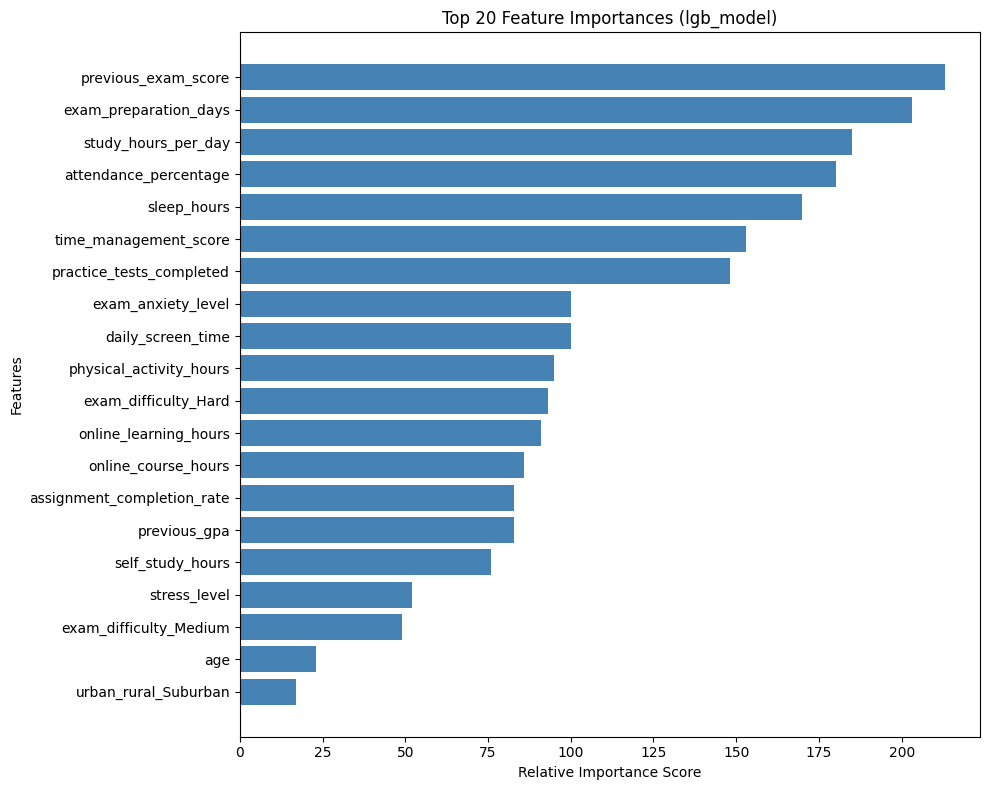

In [37]:
import matplotlib.pyplot as plt
import pandas as pd


importances = lgb_model.feature_importances_


feature_names = X_train.columns


importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

importance_df = importance_df.sort_values(by='Importance', ascending=True)


top_20_importance = importance_df.tail(20)

plt.figure(figsize=(10, 8))
plt.barh(top_20_importance['Feature'], top_20_importance['Importance'], color='steelblue')
plt.title("Top 20 Feature Importances (lgb_model)")
plt.xlabel("Relative Importance Score")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

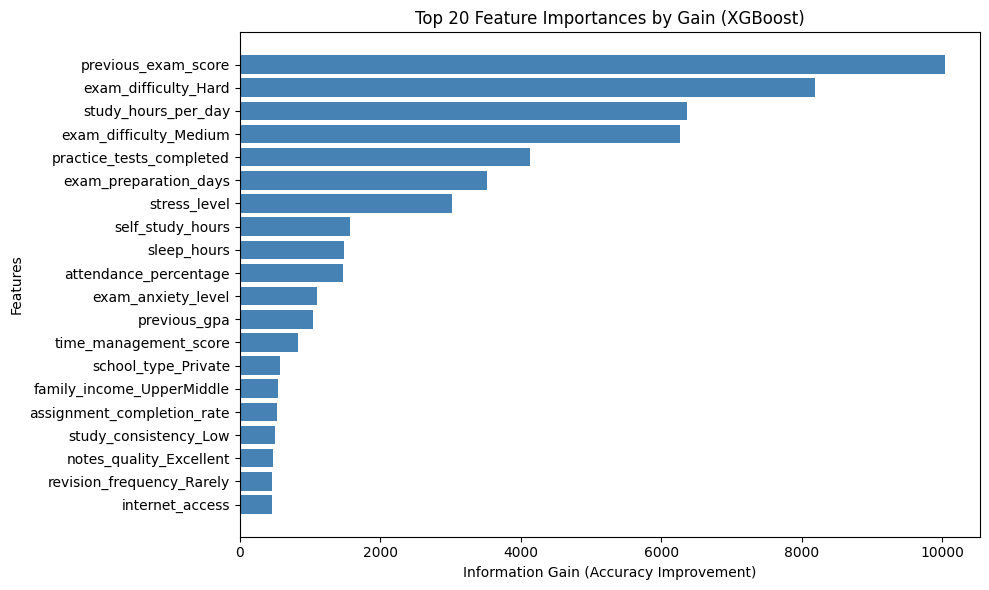

In [38]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract Gain-based importance from XGBoost
xgb_gain = xgb_model.get_booster().get_score(importance_type='gain')

# Convert to DataFrame
xgb_gain_df = pd.DataFrame({
    'Feature': list(xgb_gain.keys()), 
    'Gain': list(xgb_gain.values())
})

# Sort and keep the Top 20 features for a clean plot
xgb_gain_df = xgb_gain_df.sort_values(by='Gain', ascending=True).tail(20)

# Plot XGBoost Gain Importance
plt.figure(figsize=(10, 6))
plt.barh(xgb_gain_df['Feature'], xgb_gain_df['Gain'], color='steelblue')
plt.title("Top 20 Feature Importances by Gain (XGBoost)")
plt.xlabel("Information Gain (Accuracy Improvement)")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

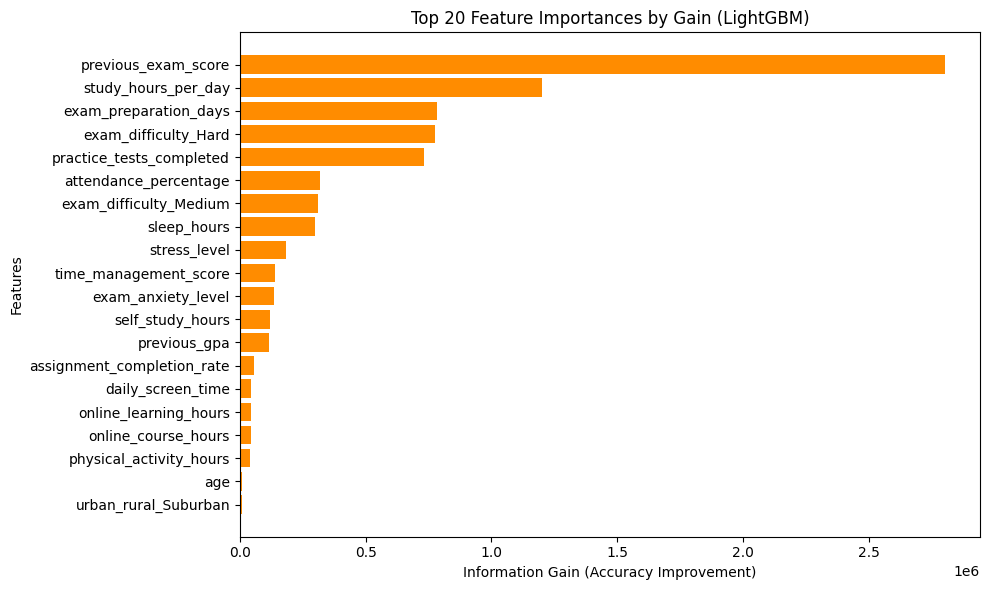

In [39]:

lgb_gain_values = lgb_model.booster_.feature_importance(importance_type='gain')


lgb_gain_df = pd.DataFrame({
    'Feature': X_train.columns, 
    'Gain': lgb_gain_values
})


lgb_gain_df = lgb_gain_df.sort_values(by='Gain', ascending=True).tail(20)


plt.figure(figsize=(10, 6))
plt.barh(lgb_gain_df['Feature'], lgb_gain_df['Gain'], color='darkorange')
plt.title("Top 20 Feature Importances by Gain (LightGBM)")
plt.xlabel("Information Gain (Accuracy Improvement)")
plt.ylabel("Features")
plt.tight_layout()
plt.show()